In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score, silhouette_samples
from sklearn.decomposition import PCA

import umap
import os
import pickle

# Optimal Preprocessing for k-means

In [58]:
df_pre_PCA = pd.read_csv('../PART1/ddos_dataset_pre_PCA.csv', index_col=0)
df_pd = df_pre_PCA.copy()

In [59]:
label_counts = df_pd['label'].value_counts()
df_labels = df_pd['label'].values

In [60]:
# Dropping categorical or useless features
columnsToDrop = ["Flow ID","Source IP", "Source Port", "Destination IP", "Destination Port", "Timestamp","label"]
df_pd = df_pd.drop(columns=columnsToDrop)

In [61]:
df_np = df_pd.to_numpy()

df_euclidean_np = StandardScaler().fit_transform(df_np)
df_euclidean_pd = pd.DataFrame(df_euclidean_np, columns=df_pd.columns)

df_cosine_np = normalize(df_np, norm='l2')
df_cosine_pd = pd.DataFrame(df_cosine_np, columns=df_pd.columns)

In [62]:
# create this folder to save already computed results
if not os.path.exists("./saved_results"):
    os.makedirs("./saved_results")

### Performing k-means clustering with **12** clusters, corresponding to the number of labels we have, and then computing the relevant metrics.

In [63]:
def k_means_with_info(df, df_labels, k, metric, n_samples=None, print_info=True):
    k_means = KMeans(n_clusters=k,init='k-means++', n_init=10, random_state=42)
    cluster_labels = k_means.fit_predict(df)

    inertia = k_means.inertia_
    inertia_per_sample = inertia / len(df)
    silhouette_val = silhouette_score(df, cluster_labels, metric=metric, sample_size=n_samples, random_state=42)
    rand_score_val = rand_score(df_labels, cluster_labels)
    adj_rand_score_val = adjusted_rand_score(df_labels, cluster_labels)
    unique, counts = np.unique(cluster_labels, return_counts=True)
    cluster_sizes = counts

    results = {
        'k': k,
        'metric': metric,
        'inertia': round(inertia, 2),
        'inertia_per_sample': round(inertia_per_sample, 2),
        'silhouette': round(silhouette_val, 2),
        'RI': round(rand_score_val, 2),
        'ARI': round(adj_rand_score_val, 2),
        'cluster_labels': cluster_labels,
        'cluster_sizes': cluster_sizes,
        'centroids' : k_means.cluster_centers_,
        'n_iter' : k_means.n_iter_
    }

    if print_info:
        print(f'## k-Means results: (k={k}, metric: {metric})')
        print("---")
        print(f"Mean squared distances from centroid: {results['inertia_per_sample']}")
        print(f"k-means clustering error (Inertia): {results['inertia']}")
        print(f"Silhouette Score : {results['silhouette']}")
        print(f"Rand Index (RI): {results['RI']}")
        print(f"Adjusted Rand Index (ARI): {results['ARI']}")
        print(f"Size of each cluster: {results['cluster_sizes']}")
        print(f"Number of iterations: {results['n_iter']}\n")

    return results

In [8]:
kmeans_euclidean_12 = k_means_with_info(df_euclidean_np, df_labels, k=12, metric='euclidean',n_samples=None, print_info=True)
kmeans_cosine_12 = k_means_with_info(df_cosine_np, df_labels, k=12, metric='cosine',n_samples=None, print_info=True)

## k-Means results: (k=12, metric: euclidean)
---
Mean squared distances from centroid: 26.34
k-means clustering error (Inertia): 1691839.25
Silhouette Score : 0.47
Rand Index (RI): 0.81
Adjusted Rand Index (ARI): 0.35
Size of each cluster: [  727 23677 18986  7600  2470    28   496  2121  4063  1186    41  2844]
Number of iterations: 8

## k-Means results: (k=12, metric: cosine)
---
Mean squared distances from centroid: 0.01
k-means clustering error (Inertia): 453.02
Silhouette Score : 0.97
Rand Index (RI): 0.5
Adjusted Rand Index (ARI): 0.1
Size of each cluster: [47333  8683  2325  2085  1362   381   321   279   877   288   172   133]
Number of iterations: 6



# K tuning

In [64]:
def k_tuning(checkpoint_file, start_k, end_k, df, df_labels, metric, n_samples=None):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            k_results = pickle.load(f)
        start_k = max(k_results["k"]) + 1
    else:
        k_results = {"k" : [],"metric" : [],"inertia" : [],"inertia_per_sample": [],"silhouette" : [],"RI" : [],"ARI" : [],"cluster_labels": [],"cluster_sizes": []}
    if start_k < end_k+1:
        print(f"Resume from k = {start_k}")
        for n_cl in range(start_k, end_k+1):
            results = k_means_with_info(df,df_labels,n_cl,metric,n_samples,False)
            k_results["k"].append(results["k"])
            k_results["metric"].append(results["metric"])
            k_results["inertia"].append(results["inertia"])
            k_results["inertia_per_sample"].append(results["inertia_per_sample"])
            k_results["silhouette"].append(results["silhouette"])
            k_results["RI"].append(results["RI"])
            k_results["ARI"].append(results["ARI"])
            k_results["cluster_labels"].append(results["cluster_labels"])
            k_results["cluster_sizes"].append(results["cluster_sizes"])

            with open(checkpoint_file, "wb") as f:
                pickle.dump(k_results, f)
            print(f"Checkpoint saved for k = {n_cl}")

        print("Loop terminated.")
    else:
        print("Already terminated.")
    return k_results

Calculating euclidean results for k between 2 and 40

In [65]:
results_euclidean = k_tuning("./saved_results/k_means_euclidean.pkl", 2, 40, df_euclidean_np, df_labels, "euclidean")

Already terminated.


Calculating cosine results for k between 2 and 40

In [66]:
results_cosine = k_tuning("./saved_results/k_means_cosine.pkl", 2, 40, df_cosine_np, df_labels, "cosine")

Already terminated.


## Plot metrics

In [67]:
def plot_metrics(silhouette_list, k_list, inertia_list, ri_list, ari_list, metric):
    fig, axs = plt.subplots(2, 2, figsize=(14, 7))

    fig.suptitle(f"Clustering Performance Analysis - Metric: {metric}")

    # Silhouette score
    best_silhouette_idx = np.argmax(silhouette_list)
    best_silhouette = silhouette_list[best_silhouette_idx]
    best_silhouette_k = k_list[best_silhouette_idx]
    axs[0, 0].set_title(f'Silhouette score (best k={best_silhouette_k}, silhouette={best_silhouette:.2f})')
    axs[0, 0].plot(k_list, silhouette_list, marker='o', markersize=5)
    axs[0, 0].scatter(best_silhouette_k, best_silhouette, color='r', marker='x', s=90)
    axs[0, 0].set_xlabel('Number of clusters')
    axs[0, 0].set_ylabel('Silhouette score')
    axs[0, 0].grid(alpha=0.5)

    # k-Means clustering error'
    best_inertia_idx = np.argmin(inertia_list)
    best_inertia = inertia_list[best_inertia_idx]
    best_inertia_k = k_list[best_inertia_idx]
    axs[0, 1].plot(k_list, inertia_list, marker='o', markersize=5)
    axs[0, 1].scatter(best_inertia_k, best_inertia, color='r', marker='x', s=90)
    axs[0, 1].set_title(f'k-Means clustering error (best k={best_inertia_k}, c.e.={best_inertia:.2e})')
    axs[0, 1].set_xlabel('Number of clusters')
    axs[0, 1].set_ylabel('k-Means clustering error')
    axs[0, 1].grid(alpha=0.5)

    # Rand Index (RI)
    best_ri_idx = np.argmax(ri_list)
    best_ri = ri_list[best_ri_idx]
    best_ri_k = k_list[best_ri_idx]
    axs[1, 0].plot(k_list, ri_list, marker='o', markersize=5)
    axs[1, 0].scatter(best_ri_k, best_ri, color='r', marker='x', s=90)
    axs[1, 0].set_title(f'Rand Index (RI) (best k={best_ri_k}, c.e.={best_ri:.2f})')
    axs[1, 0].set_xlabel('Number of clusters')
    axs[1, 0].set_ylabel('RI')
    axs[1, 0].grid(alpha=0.5)

    # Adjusted Rand Index (ARI)
    best_ari_idx = np.argmax(ari_list)
    best_ari = ari_list[best_ari_idx]
    best_ari_k = k_list[best_ari_idx]
    axs[1, 1].plot(k_list, ari_list, marker='o', markersize=5)
    axs[1, 1].scatter(best_ari_k, best_ari, color='r', marker='x', s=90)
    axs[1, 1].set_title(f'Adjusted Rand Index (ARI) (best k={best_ari_k}, c.e.={best_ari:.2f})')
    axs[1, 1].set_xlabel('Number of clusters')
    axs[1, 1].set_ylabel('ARI')
    axs[1, 1].grid(alpha=0.5)


    plt.tight_layout()
    plt.show()

### Plot cosine metrics (for k between 2 and 40)

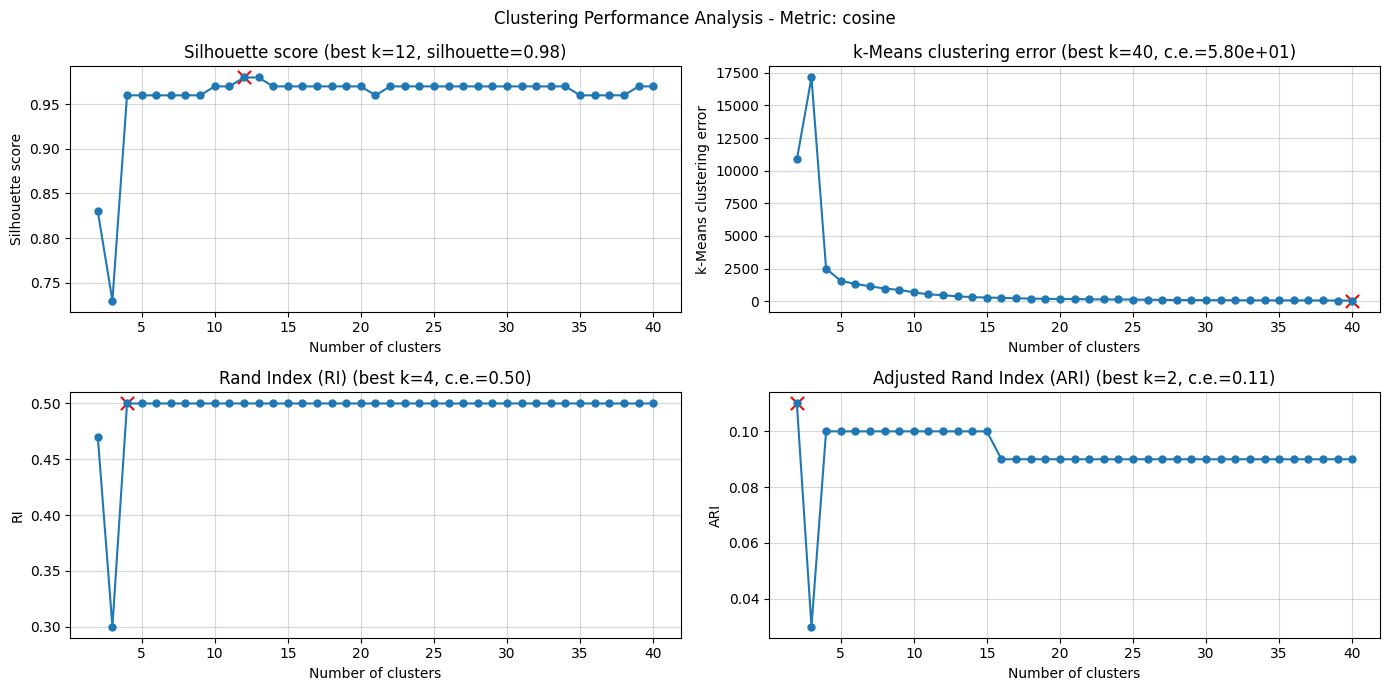

In [68]:
plot_metrics(results_cosine["silhouette"], results_cosine["k"], results_cosine["inertia"], results_cosine["RI"],results_cosine["ARI"], "cosine")

#### Analysis:

- **Approach** : We used L2 normalization followed by Euclidean K-Means. This 'pseudo-cosine' method groups data based on vector direction (feature ratios) rather than magnitude.

- **Results**: We achieved a very high Silhouette Score ($~0.98$), indicating well-defined clusters. However, the ARI was very low (~0.1), meaning these clusters do not match the ground truth labels.

- **Main Issue**: The algorithm produced one 'mega-cluster' holding nearly all the samples (47k over 64k total). This occurs because Cosine similarity ignores traffic volume (total bytes/packets), which is a key factor in distinguishing DDoS attacks.

Conclusion: In this context, a high Silhouette score is misleading. It confirms the data is mathematically grouped, but the clusters are not useful for identifying specific attack families.

### Plot euclidean metrics (for k between 2 and 40)

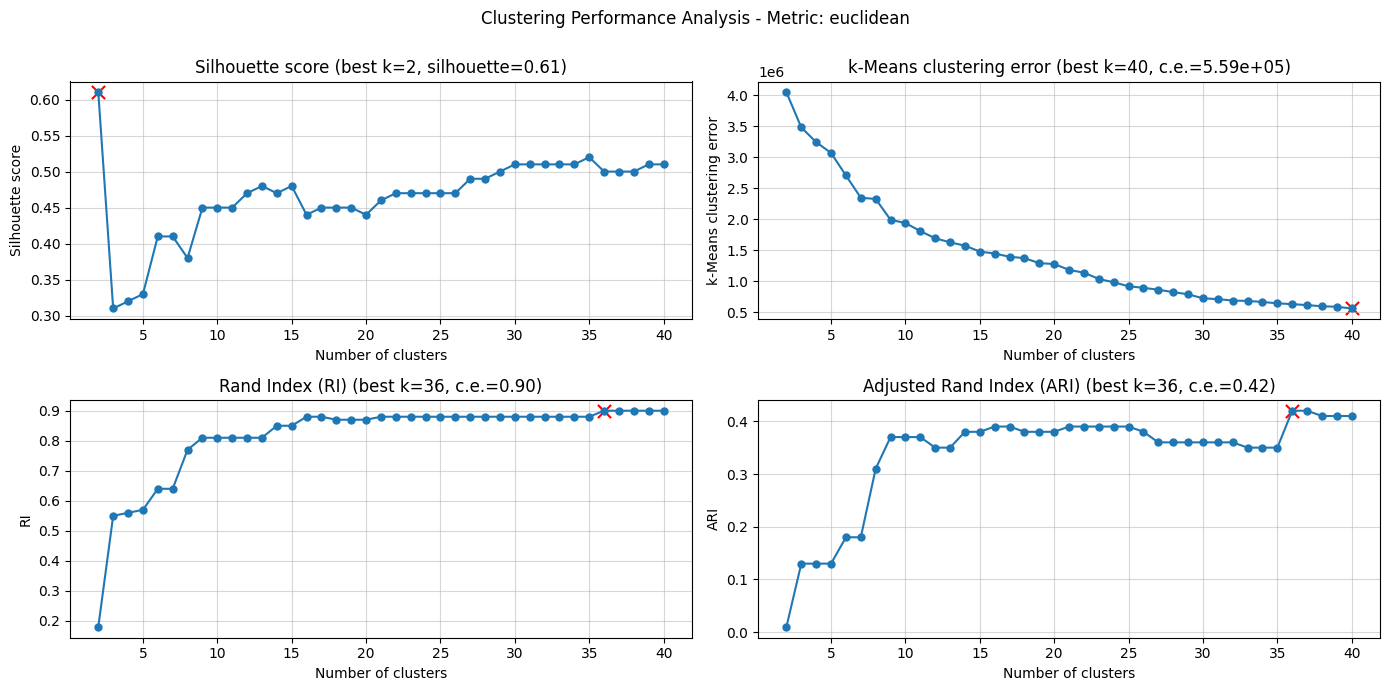

In [69]:
plot_metrics(results_euclidean["silhouette"], results_euclidean["k"], results_euclidean["inertia"], results_euclidean["RI"],results_euclidean["ARI"], "euclidean")

#### Analysis:

- **K-Means Clustering Error**: as expected, the error decreases as $k$ increases. An "elbow," is observed at $k=9$.
- **Rand Index (RI) & Adjusted Rand Index (ARI)**: Both external validation metrics show significant improvement up to $k=9$. While a slight peak occurs around $k=36$, the heatmap analysis reveals that this higher value leads to over-clustering, unnecessarily dividing single attack types into multiple redundant clusters without improving class separation.
- **Silhouette Score**: While the global maximum occurs at $k=2$ (indicating a binary split in the data). The score shows a big improvement and stabilizes starting at $k=9$. While higher scores appear for $k>30$, these do not translate to better grouping of attack families.

Conclusion: An optimal value of $k$ is between 9 and 15. This selection is supported by the "elbow" observed in the Inertia, ARI, and Silhouette graphs. Increasing $k$ beyond this point results in excessive fragmentation of classes.

## Plot cluster - label heatmap

In [70]:
def plot_label_cluster_heatmap(cluster_labels, true_labels, normalize=True):
    df = pd.DataFrame({"label": true_labels,"cluster": cluster_labels})
    table = (df.groupby("label")["cluster"].value_counts().unstack(fill_value=0))

    if normalize:
        table = table.div(table.sum(axis=1), axis=0) *100

    plt.figure(figsize=(22,7))
    sns.heatmap(table, 
                cmap="viridis", 
                cbar=True, 
                cbar_kws={"ticks": np.linspace(0, 100 if normalize else table.values.max(), 5)}, 
                vmin=0, 
                vmax=100 if normalize else table.values.max(), 
                linewidths=0.1, 
                linecolor='black', 
                fmt="", 
                annot=table.map(lambda v: f"{v:.2f}".rstrip('0').rstrip('.')) if normalize else table,
                annot_kws={"size": 10})

    plt.xlabel("Cluster")
    plt.ylabel("Label")
    if normalize:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (in %)")
    else:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (num of samples)")

    plt.tight_layout()
    plt.show()

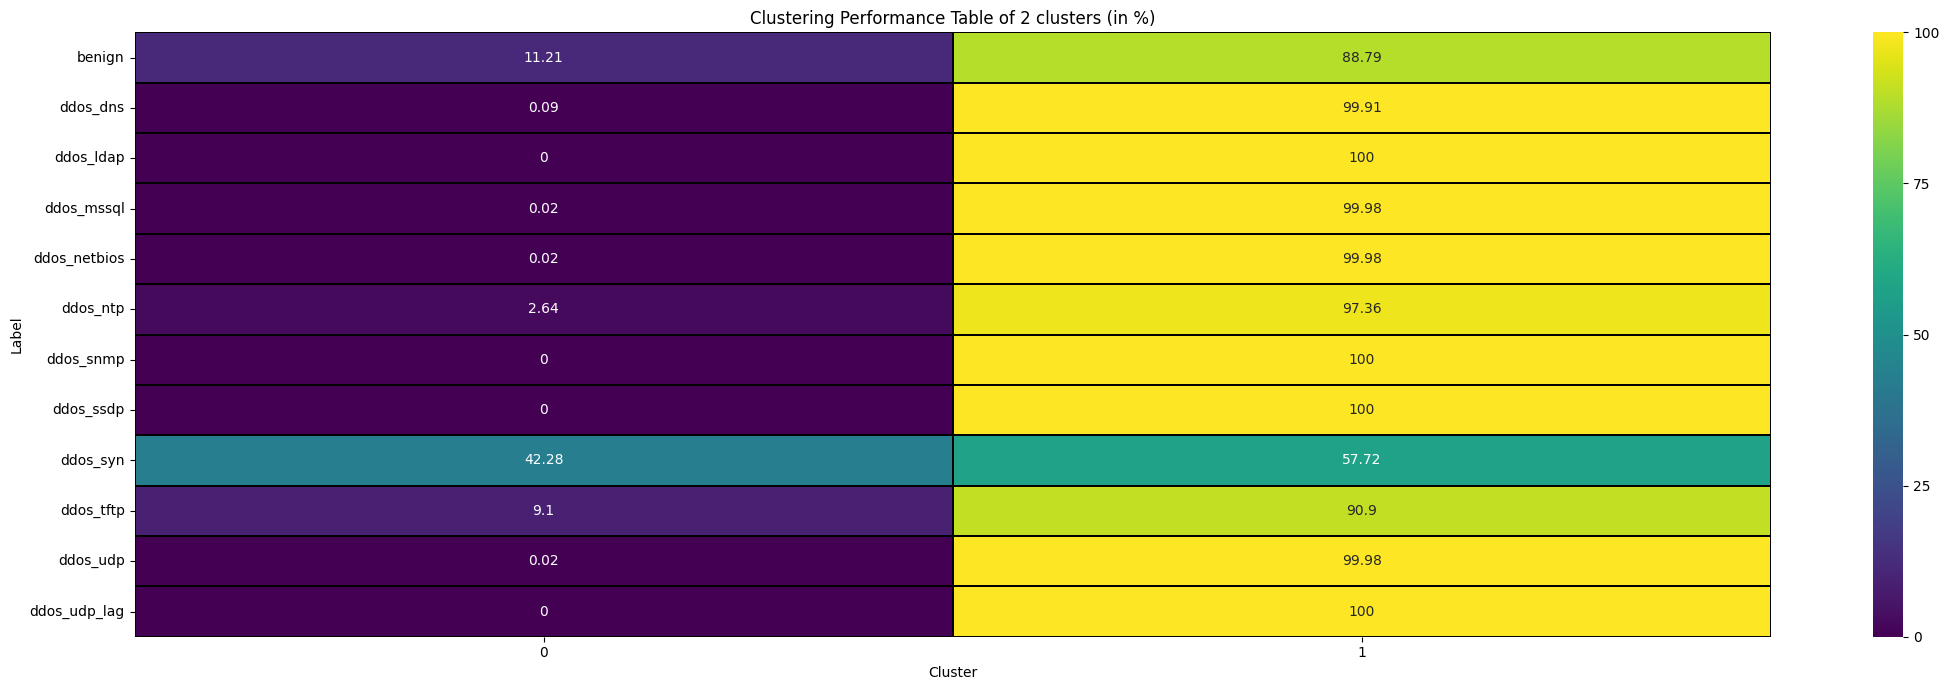

In [71]:
plot_label_cluster_heatmap(results_euclidean["cluster_labels"][2-2],df_labels,True)

The 2-cluster heatmap demonstrates that this configuration fails to achieve also a basic split between benign and malicious traffic. Instead, Cluster 1 acts as a "catch-all" group containing over 88% of benign flows and nearly 100% of most attack types. Cluster 0 achieves to group a good portion of SYN attack

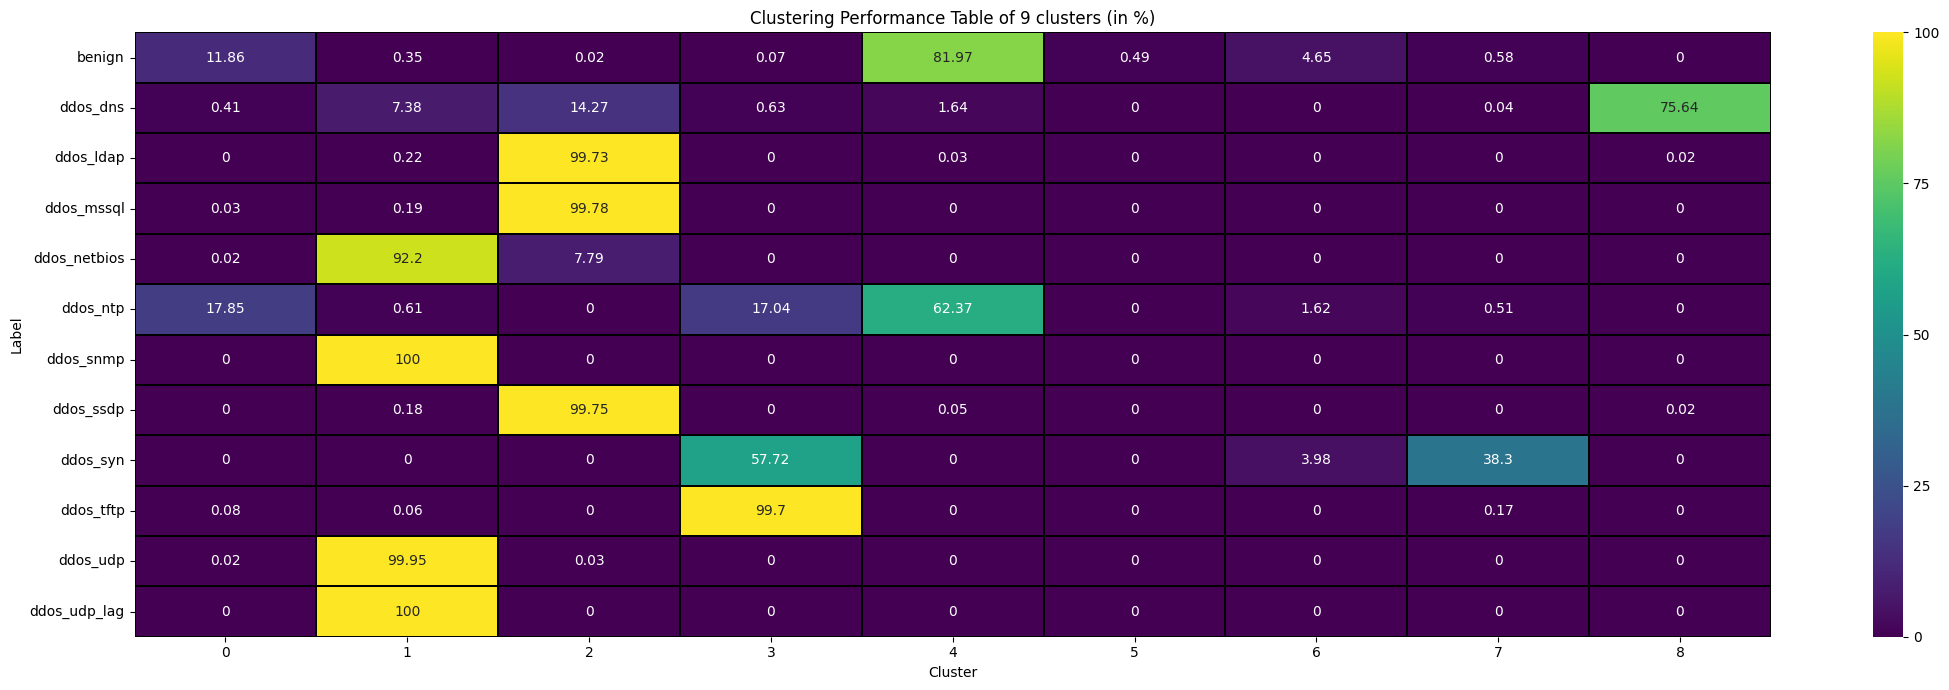

In [72]:
plot_label_cluster_heatmap(results_euclidean["cluster_labels"][9-2],df_labels,True)

The 9-cluster heatmap identifies the "elbow" point where the ARI,Silhouette and inertia first stabilize, effectively grouping major attack families like LDAP/MSSQL/SSDP (Cluster 2), NetBIOS/SNMP/UDP/UDPLAG (Cluster 1), TFTP/SYN (Cluster 3) and NTP/BENIGN (Cluster 4) with high purity.

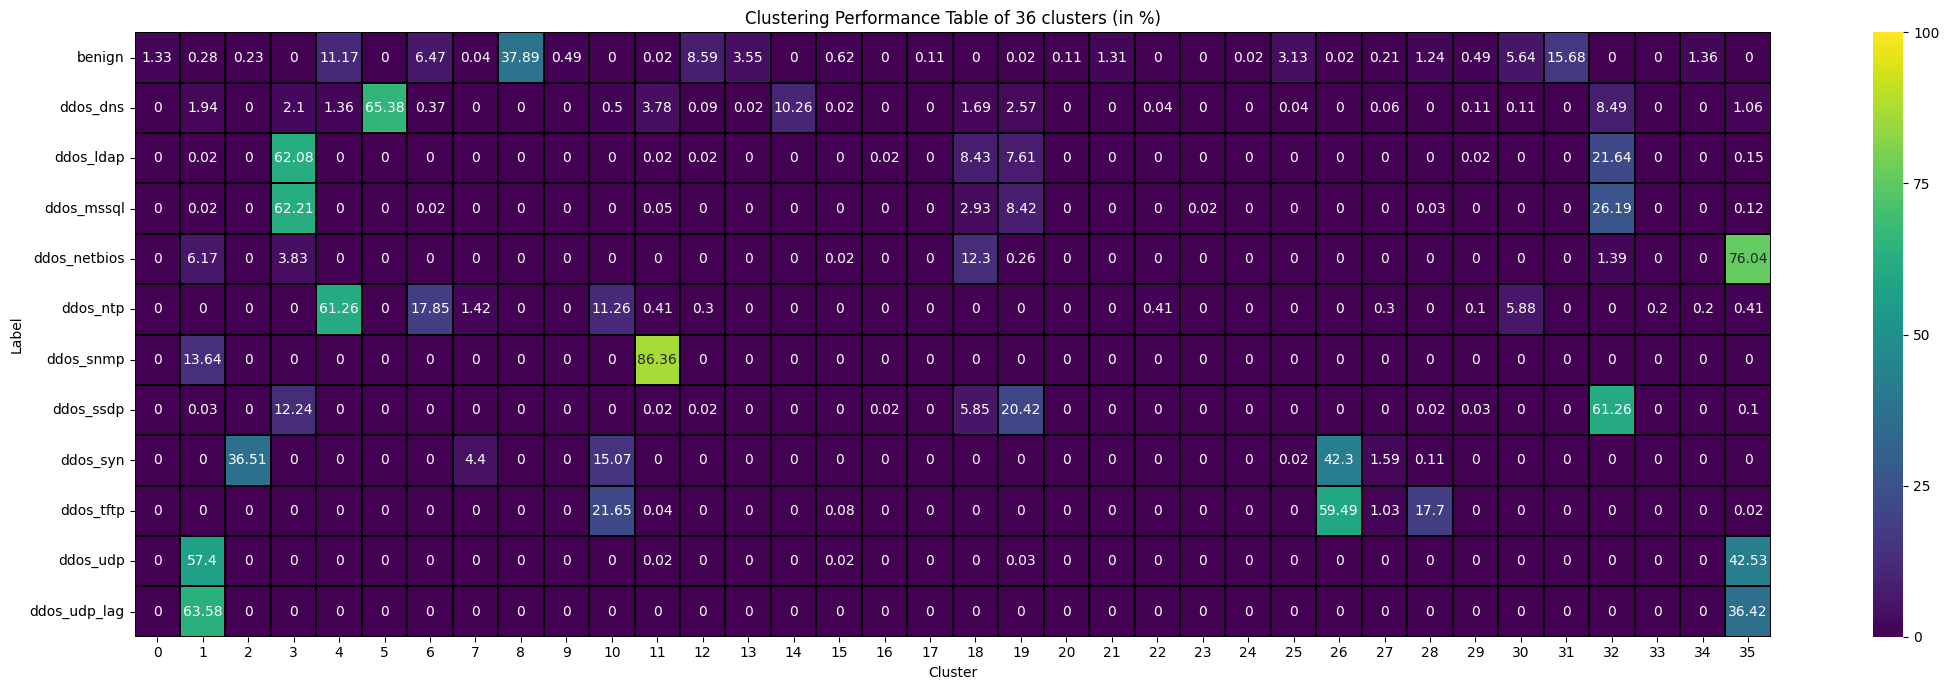

In [73]:
plot_label_cluster_heatmap(results_euclidean["cluster_labels"][36-2],df_labels,True)

The 32-cluster heatmap results in significant over-clustering. Most of the attack types become excessively fragmented across multiple clusters, many of which remain nearly empty. There is actually no improvement compared to lower values of $k$

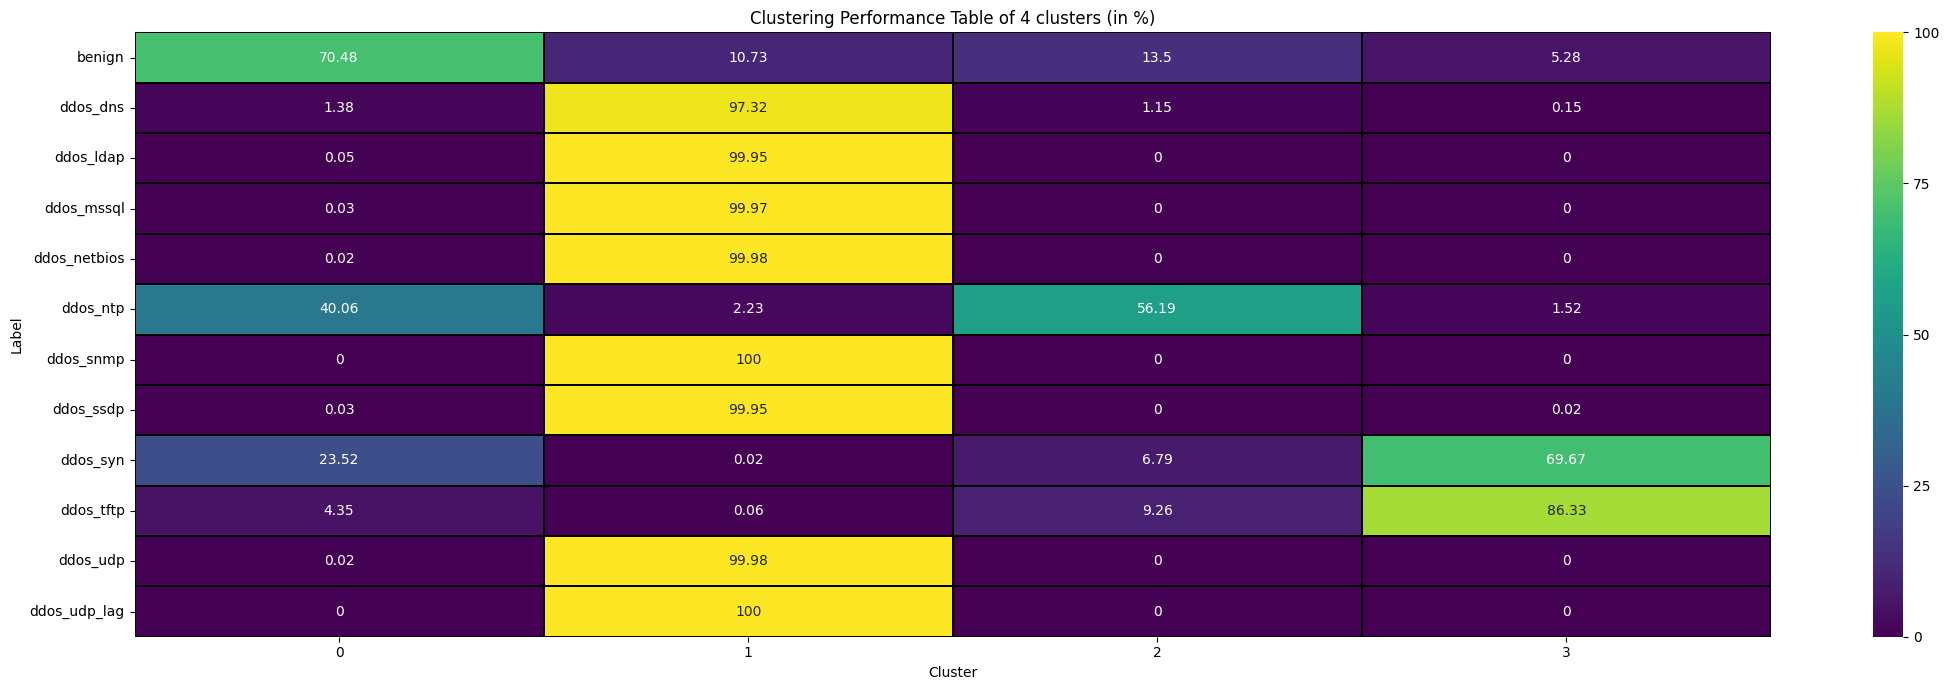

In [76]:
plot_label_cluster_heatmap(results_cosine["cluster_labels"][4-2],df_labels,True)

# Calculating best_k and its k_means metrics

In [23]:
best_k = 9
best_metric = 'euclidean'
best_df_np = df_euclidean_np

In [24]:
results_best_k = k_means_with_info(df=best_df_np, df_labels=df_labels, k=best_k, metric=best_metric, n_samples=None, print_info=True)

## k-Means results: (k=9, metric: euclidean)
---
Mean squared distances from centroid: 30.98
k-means clustering error (Inertia): 1990020.31
Silhouette Score : 0.45
Rand Index (RI): 0.81
Adjusted Rand Index (ARI): 0.37
Size of each cluster: [  877 23678 18988  8614  5346    28   497  2148  4063]
Number of iterations: 13



#  Analysis of the detected clusters

### 2D plot with first 2 components of PCA

In [25]:
def plot_clustering_2d(df, cl_labels, n_cluster, metric, centroids):
    pca = PCA(n_components=2)
    df_pca = pca.fit_transform(df)

    centroids_pca = pca.transform(centroids)

    plt.figure(figsize=(14, 7))
    sns.scatterplot(x=df_pca[:,0], y=df_pca[:,1], hue=cl_labels, palette='tab10', s=30)

    plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='x', s=70, linewidths=2, color='black', label='Centroids')

    plt.title(f"K-Means Clustering ({n_cluster} cluster) PCA 2D - Metric: {metric}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 0.5), loc='center left')
    plt.tight_layout()
    plt.show()

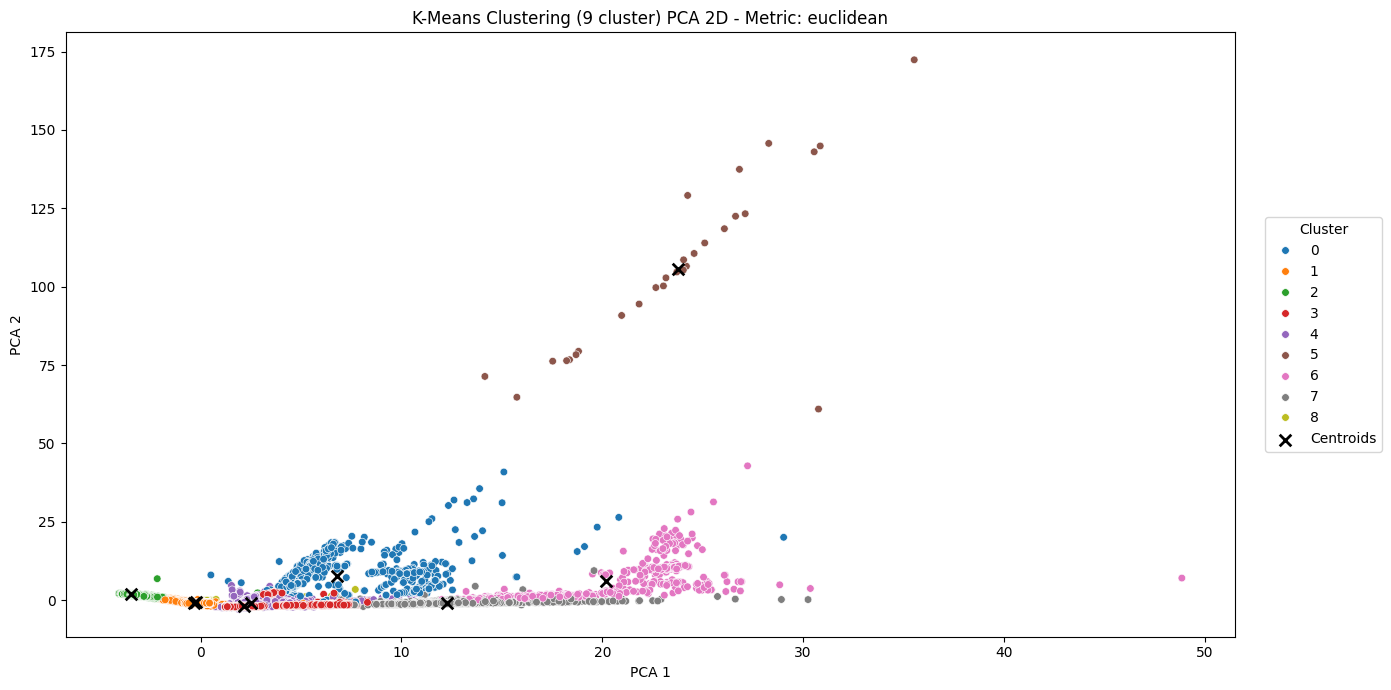

In [26]:
plot_clustering_2d(best_df_np, results_best_k["cluster_labels"], results_best_k["k"], best_metric, results_best_k["centroids"])

### 3D plot with first 3 components of PCA

In [27]:
def plot_clustering_3d(df, cl_labels, n_cluster, metric):
    pca = PCA(n_components=3)
    df_pca = pca.fit_transform(df)

    fig = plt.figure(figsize=(14, 7))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(df_pca[:,2], df_pca[:,0], df_pca[:,1], c=cl_labels, cmap='tab10', s=30)
    ax.set_title(f"K-Means Clustering ({n_cluster} cluster) PCA 3D - Metric: {metric}")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.set_zlabel("PCA 3")


    handles, labels = scatter.legend_elements(num=n_cluster)
    ax.legend(handles=handles, labels=labels, title="Cluster", bbox_to_anchor=(1.06, 0.5), loc='center left')


    plt.tight_layout()
    plt.show()

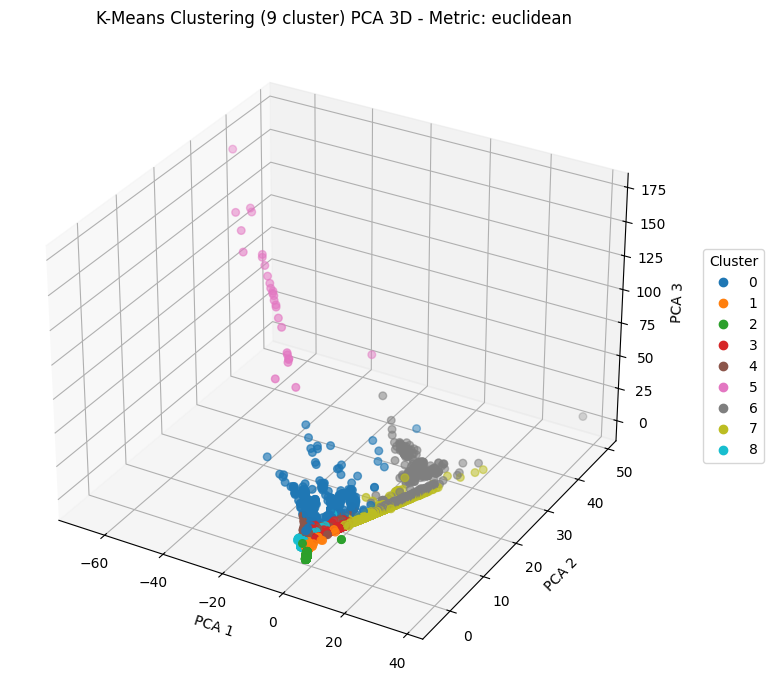

In [28]:
plot_clustering_3d(best_df_np,results_best_k["cluster_labels"],results_best_k["k"], best_metric)

### UMAP plot

In [77]:
def calculate_umap(checkpoint_file, df, cluster_labels):
  pca = PCA(n_components=20)
  df_pca = pca.fit_transform(df)
  if os.path.exists(checkpoint_file):
    with open(checkpoint_file, "rb") as f:
      df_umap = pickle.load(f)
    print(f"df_umap already calculated")
  else:
    reducer = umap.UMAP(
        n_neighbors=15,
        n_components=2,
        min_dist=0.1,
        random_state=42
    )
    df_umap = reducer.fit_transform(df_pca)
    df_umap = pd.DataFrame(data=df_umap, columns=['UMAP D1', 'UMAP D2'])
    df_umap['Clusters'] = cluster_labels
    with open(checkpoint_file, "wb") as f:
      pickle.dump(df_umap, f)
    print(f"df_umap saved in {checkpoint_file}")
  return df_umap

In [78]:
checkpointFile = f"./saved_results/k_means_df_umap_{best_metric}_{best_k}.pkl"
df_umap = calculate_umap(checkpointFile, best_df_np, results_best_k["cluster_labels"])

df_umap already calculated


In [43]:
def plot_umap(df_umap, k_list, metric):
    plt.figure(figsize=(14,7))
    sns.scatterplot(
        x='UMAP D1',
        y='UMAP D2',
        hue='Clusters',
        palette=sns.color_palette("tab10", k_list),
        data=df_umap,
        alpha=0.7)
    
    plt.title(f"Cluster visualization with UMAP - Metric: {metric}")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.grid()
    plt.legend(title="Cluster",bbox_to_anchor=(1.02, 0.5), loc='center left')
    plt.tight_layout()
    plt.show()

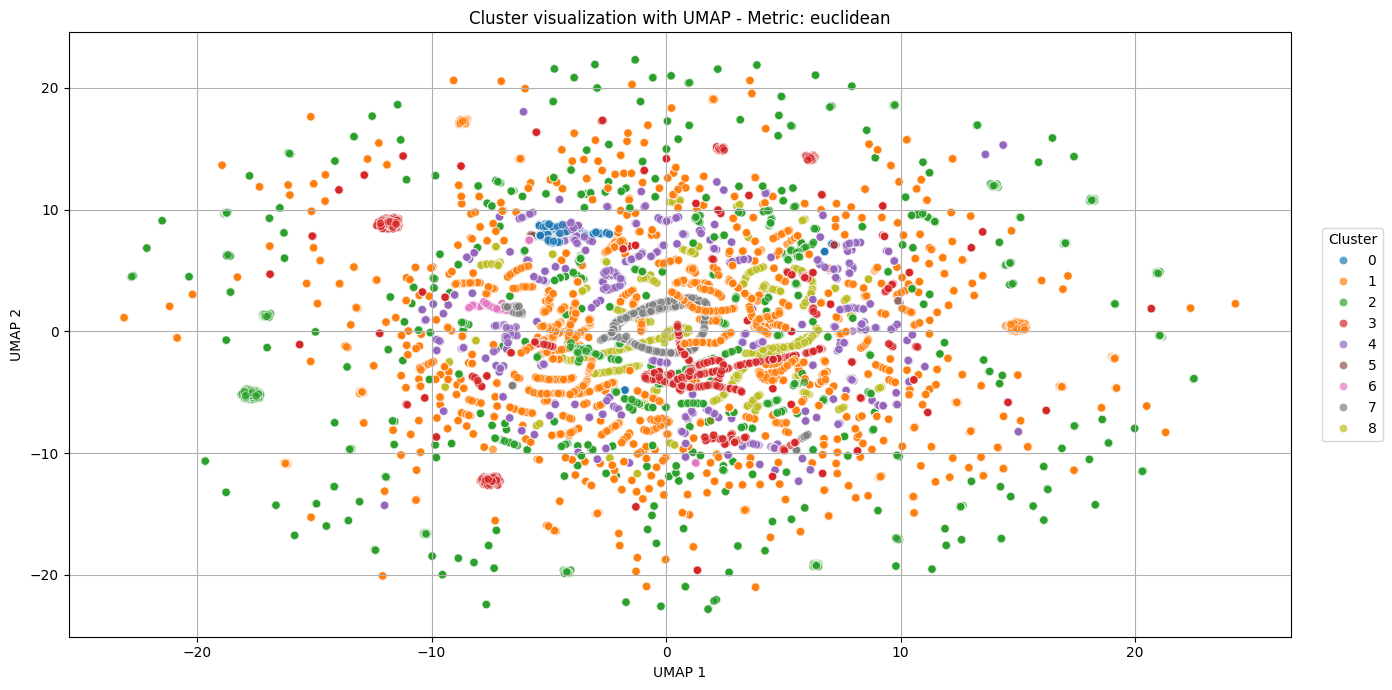

In [44]:
plot_umap(df_umap,results_best_k["k"],best_metric)

In [45]:
def plot_ecdf_comparison(cluster_sizes, ground_truth_sizes, metric):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    
    sns.ecdfplot(cluster_sizes, ax=ax[0], color='blue', lw=2)
    ax[0].set_xlabel("Number of flows per cluster")
    ax[0].set_ylabel("ECDF")
    ax[0].set_title(f"ECDF dei Cluster (Metric: {metric})")
    ax[0].grid(True, linestyle='--', alpha=0.6)
    
    sns.ecdfplot(ground_truth_sizes, ax=ax[1], color='blue', lw=2)
    ax[1].set_xlabel("Number of flow per label")
    ax[1].set_ylabel("ECDF")
    ax[1].set_title("ECDF of Ground Truth")
    ax[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.suptitle("Confront ECDF Cluster vs Ground Truth")
    
    plt.tight_layout()
    plt.show()

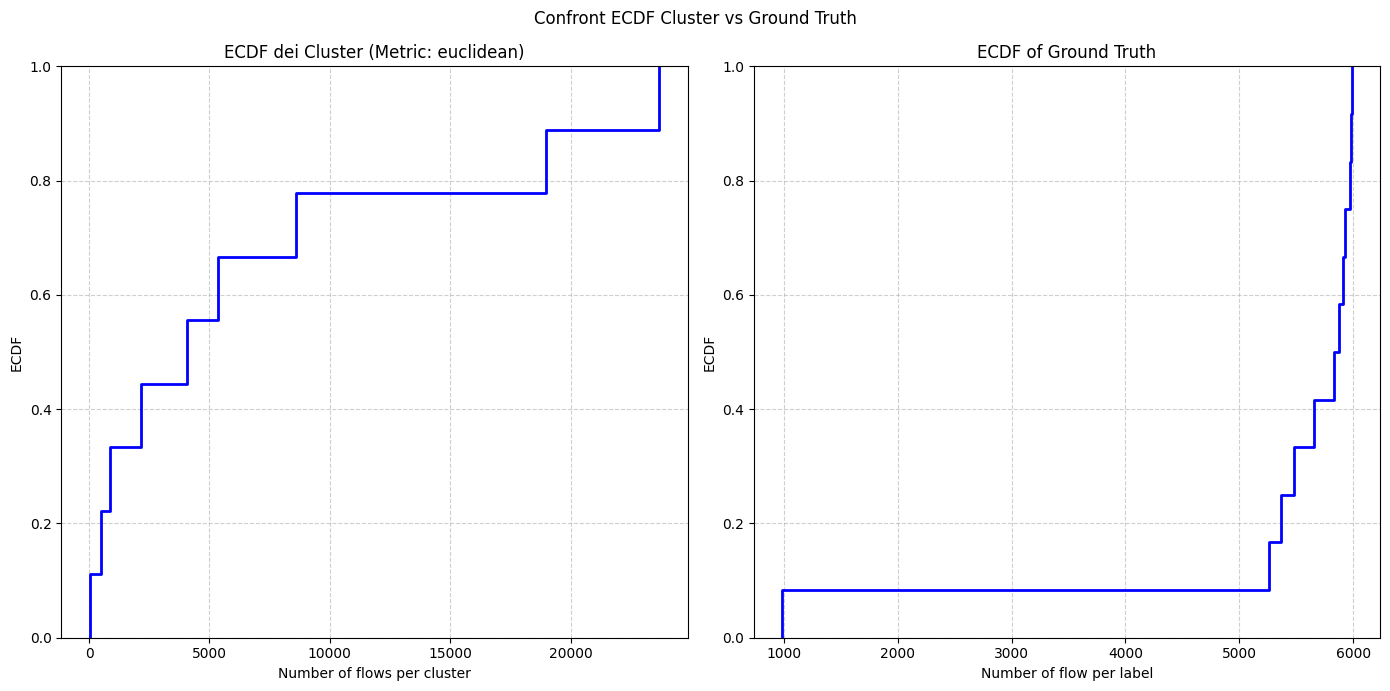

In [46]:
plot_ecdf_comparison(results_best_k['cluster_sizes'],label_counts.values,best_metric)

In [47]:
def plot_comparison_bar(cluster_sizes, ground_truth_sizes, metric):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    
    ax[0].bar(range(len(cluster_sizes)), sorted(cluster_sizes, reverse=True), color='blue', alpha=0.7)
    ax[0].set_xlabel("Cluster Index (Sorted by size)")
    ax[0].set_ylabel("Number of flows")
    ax[0].set_title(f"Cluster Size Distribution (Metric: {metric})")
    ax[0].grid(True, axis="y", linestyle='--', alpha=0.6)
    
    ax[1].bar(range(len(ground_truth_sizes)), sorted(ground_truth_sizes, reverse=True), color='blue', alpha=0.7)
    ax[1].set_xlabel("Label Index (Sorted by size)")
    ax[1].set_ylabel("Number of flows")
    ax[1].set_title("Ground Truth Label Distribution")
    ax[1].grid(True, axis="y", linestyle='--', alpha=0.6)
    
    plt.suptitle("Comparison: Cluster Volumes vs Ground Truth Volumes", fontsize=16)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

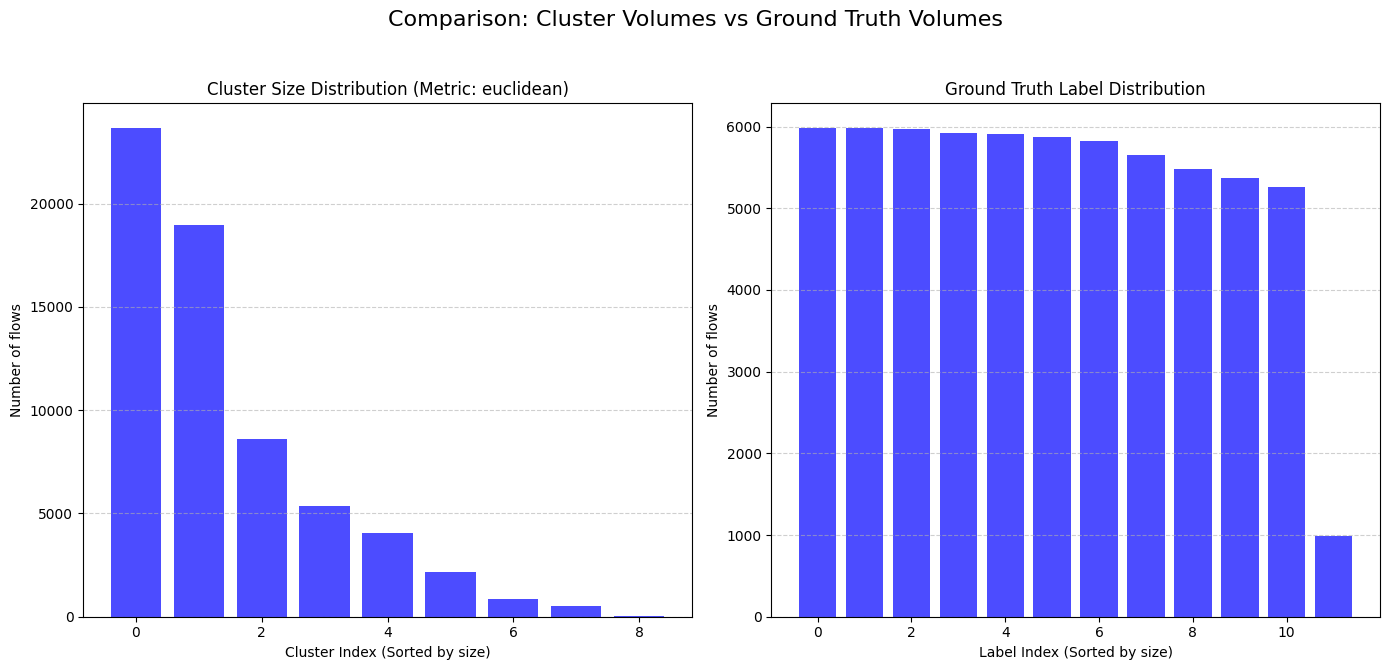

In [48]:
plot_comparison_bar(results_best_k['cluster_sizes'],label_counts.values,best_metric)

In [49]:
def silhouette_per_cluster(checkpoint_file, df, labels, metric):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            sil_cluster = pickle.load(f)
        print(f"Already calculated.")
    else:
        sil_samples = silhouette_samples(df, labels, metric=metric)

        sil_cluster_list = []
        for c in np.unique(labels):
            sil_cluster_list.append(sil_samples[labels == c].mean())
        
        sil_cluster = np.array(sil_cluster_list)

        with open(checkpoint_file, "wb") as f:
            pickle.dump(sil_cluster, f)
        print(f"Silhouette per cluster saved in {checkpoint_file}")

    return sil_cluster

In [50]:
checkpointFile = f"./saved_results/k_means_sil_{best_metric}_clusters_{best_k}.pkl"
sil_clusters = silhouette_per_cluster(checkpointFile, best_df_np,results_best_k['cluster_labels'],metric=best_metric)

Silhouette per cluster saved in ./saved_results/k_means_sil_euclidean_clusters_9.pkl


In [51]:
def plot_silhouette_per_cluster(sil_cluster, metric):
    plt.figure(figsize=(14,7))
    plt.bar(range(len(sil_cluster)), sil_cluster)
    plt.axhline(np.mean(sil_cluster), linestyle='--')
    plt.xlabel("Cluster ID")
    plt.ylabel("Mean silhouette")
    plt.title(f"Mean silhouette per cluster - Metric: {metric}")
    plt.grid(axis="y")
    plt.show()

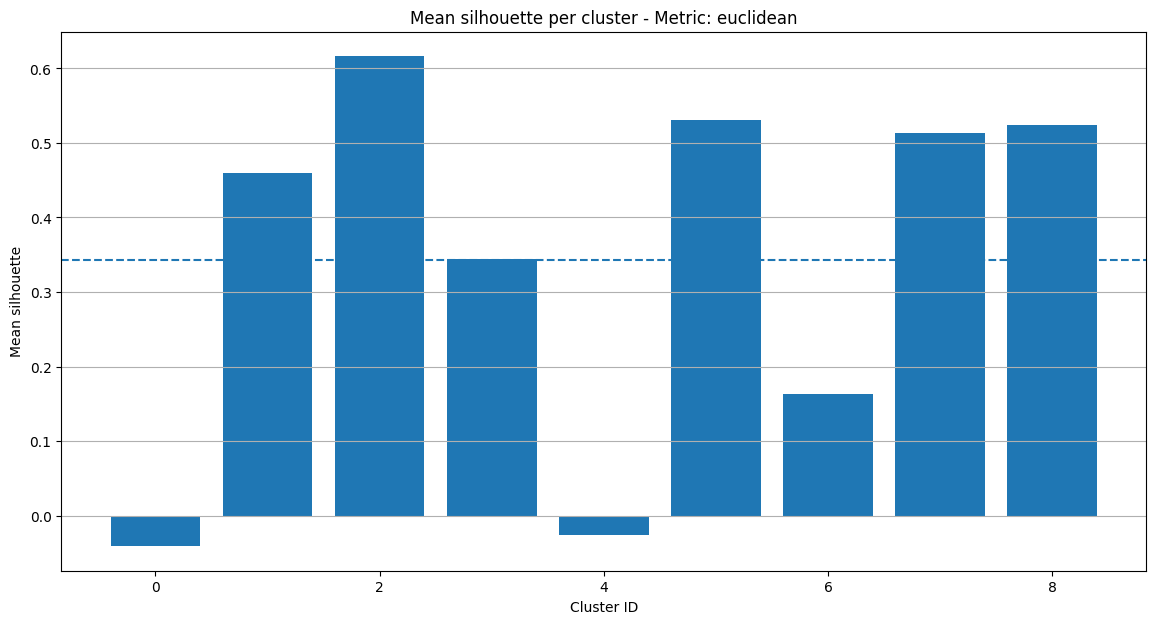

In [52]:
plot_silhouette_per_cluster(sil_clusters,best_metric)

1. Clusters 0 and 4 (Negative Scores): 
   - The silhouette scores for Clusters 0 and 4 fall below zero, which mathematically indicates that the data points in these groups are closer to a neighboring cluster than to their assigned one. This confirms what we saw in the heatmaps where Benign traffic and NTP attacks are mixed, proving the model cannot find a boundary between them with the current features.
2. Cluster 2 (High Score): 
   - Cluster 2 displays the highest silhouette score, indicating a compact and well-defined group. However, this confirms that LDAP, MSSQL, and SSDP are so similar that they form a single family rather than distinct individual clusters.

3. Stability of Attack Isolation (Clusters 3, 7, and 8): 
    - Clusters 3, 7, and 8 show good positive scores, confirming that some attacks like DNS or SYN are distinct and well-separated from the rest of the dataset. These represent the most distinct and stable patterns found by the algorithm.